# NumCompute_Stream: Demo of Campus Energy Usage

This notebook demonstrates the classification with the NumComputeStream package. It uses a small **Synthetic Campus Energy Dataset** for this assignment. The data records are illustrative and are not real measurements.

The target is `HighUsage`, a binary label indicating whether a record represents high energy usage. The notebook reads the CSV through the custom I/O function, processes data in chunks, evaluates the current model before training and visualizes the results.


In [20]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from numcompute_stream.io import load_csv_chunks
from numcompute_stream.preprocessing import StandardScaler
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualize import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth

project_root = Path.cwd()
if not (project_root / "numcompute_stream").is_dir():
    project_root = project_root.parent
if not (project_root / "numcompute_stream").is_dir():
    raise FileNotFoundError("Could not find numcompute_stream/. Open this notebook from the repository or demo folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

csv_path = project_root / "assets" / "demo.csv"
if not csv_path.exists():
    csv_path = project_root / "assets" / "stream_demo.csv"
output_dir = project_root / "demo" / "outputs"
output_dir.mkdir(exist_ok=True)
print("CSV exists:", csv_path.is_file())


CSV exists: True


## 1. Inspect and loading the CSV data

The synthetic dataset contains four numeric features: outdoor temperature, occupancy, hour of day and whether the day is a weekend. `HighUsage` is the target column. `load_csv_chunks()` returns each chunk as a two-dimensional array along with its column names.


In [24]:
CHUNK_SIZE = 30
FEATURE_COLUMNS = ["TemperatureC", "Occupancy", "HourOfDay", "IsWeekend"]
TARGET_COLUMN = "HighUsage"

first_chunk, columns = next(load_csv_chunks(str(csv_path), chunk_size=CHUNK_SIZE))
print("Columns:", columns)
print("First chunk shape:", first_chunk.shape)
print("First five rows:")
print(first_chunk[:5])

print("Features:", FEATURE_COLUMNS)
print("Target:", TARGET_COLUMN)


Columns: ['TemperatureC', 'Occupancy', 'HourOfDay', 'IsWeekend', 'HighUsage']
First chunk shape: (30, 5)
First five rows:
[['29.1' '55' '0' '0' '1']
 ['35.4' '22' '7' '0' '1']
 ['22.6' '47' '14' '0' '1']
 ['18.6' '103' '21' '0' '1']
 ['12.7' '34' '4' '0' '0']]
Features: ['TemperatureC', 'Occupancy', 'HourOfDay', 'IsWeekend']
Target: HighUsage


## 2. Build the streaming pipeline

The pipeline standardises the numeric features and passes them to a decision tree classifier. The tree uses buffered retraining, waiting until enough new samples have accumulated before fitting again. A helper function creates a fresh pipeline for each buffer-size experiment so that the main model settings remain consistent.


In [25]:
def build_pipeline(buffer_size=60):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("tree", DecisionTreeClassifier(
            max_depth=5, min_samples_split=2, buffer_size=buffer_size,
            criterion="gini", random_state=42,
        )),
    ])

BUFFER_SIZE = 60
pipeline = build_pipeline(BUFFER_SIZE)
trainer = StreamTrainer(pipeline, window_size=CHUNK_SIZE)
print("Pipeline and StreamTrainer are ready.")
print("Main tree buffer size:", BUFFER_SIZE)


Pipeline and StreamTrainer are ready.
Main tree buffer size: 60


## 3. Define the chunk-processing workflow

Each chunk is evaluated before it is added to training. This is called test-then-train evaluation and gives a more realistic view of performance on incoming data. At the beginning, the tree has not been trained, so there are no predictions to score. Once trained, predictions are recorded, metrics are logged and the chunk is passed to `fit_chunk()`.


In [26]:
def read_chunks(path, chunk_size):
    """Yield numeric feature arrays and binary target labels from CSV chunks."""
    for raw, chunk_columns in load_csv_chunks(str(path), chunk_size=chunk_size):
        required = FEATURE_COLUMNS + [TARGET_COLUMN]
        missing = [name for name in required if name not in chunk_columns]
        if missing:
            raise ValueError(f"CSV is missing required columns: {missing}")
        feature_indices = [chunk_columns.index(name) for name in FEATURE_COLUMNS]
        target_index = chunk_columns.index(TARGET_COLUMN)
        X = raw[:, feature_indices].astype(float)
        y = raw[:, target_index].astype(int)
        if not np.isin(y, [0, 1]).all():
            raise ValueError("HighUsage must contain binary labels 0 or 1")
        yield X, y

def run_stream(path, chunk_size=30, buffer_size=60, verbose=True):
    """Evaluate each chunk before training and return history and predictions."""
    stream_trainer = StreamTrainer(build_pipeline(buffer_size), window_size=chunk_size)
    all_true, all_pred = [], []
    for chunk_number, (X_chunk, y_chunk) in enumerate(read_chunks(path, chunk_size), start=1):
        was_trained = stream_trainer.model.root is not None
        if was_trained:
            predictions = stream_trainer.pipeline.predict(X_chunk)
            all_true.extend(y_chunk.tolist())
            all_pred.extend(np.asarray(predictions, dtype=int).tolist())
        record = stream_trainer.score_chunk(X_chunk, y_chunk)
        stream_trainer.fit_chunk(X_chunk, y_chunk)
        if verbose:
            accuracy = record.get("accuracy")
            accuracy_text = "cold start" if accuracy is None else f"{accuracy:.3f}"
            train_time = stream_trainer.history[-1]["training_time"]
            print(f"Chunk {chunk_number:02d} | samples={len(y_chunk):3d} | accuracy={accuracy_text:>10} | training={train_time:.4f}s")
    return stream_trainer, np.asarray(all_true, dtype=int), np.asarray(all_pred, dtype=int)


## 4. Run the streaming experiment

The CSV is processed chunk by chunk. With a buffer size of 60 and a chunk size of 30, the tree accumulates data across chunks before retraining. The metrics shown below are generated by the current run.


In [27]:
trainer, y_true, y_pred = run_stream(csv_path, chunk_size=CHUNK_SIZE, buffer_size=BUFFER_SIZE)
print("\nRun summary")
print("Chunks processed:", len(trainer.history))
print("Samples evaluated after model training:", len(y_true))
last_scored = next((r for r in reversed(trainer.history) if r.get("cumulative_accuracy") is not None), None)
if last_scored is not None:
    for metric in ("cumulative_accuracy", "cumulative_precision", "cumulative_recall", "cumulative_f1", "cumulative_auc"):
        value = last_scored.get(metric)
        print(f"{metric}: {'N/A' if value is None else f'{value:.3f}'}")


Chunk 01 | samples= 30 | accuracy=cold start | training=0.0005s
Chunk 02 | samples= 30 | accuracy=cold start | training=0.0261s
Chunk 03 | samples= 30 | accuracy=     0.800 | training=0.0007s
Chunk 04 | samples= 30 | accuracy=     0.700 | training=0.0352s
Chunk 05 | samples= 30 | accuracy=     0.633 | training=0.0004s
Chunk 06 | samples= 30 | accuracy=     0.833 | training=0.0212s
Chunk 07 | samples= 30 | accuracy=     0.767 | training=0.0003s
Chunk 08 | samples= 30 | accuracy=     0.667 | training=0.0200s

Run summary
Chunks processed: 8
Samples evaluated after model training: 180
cumulative_accuracy: 0.733
cumulative_precision: 0.742
cumulative_recall: 0.725
cumulative_f1: 0.733
cumulative_auc: 0.768


## 5. Review the logged metrics

Each history record contains chunk-level accuracy, cumulative classification metrics, training time, and peak traced memory where available. The first chunk may show `None` for accuracy because the tree has not yet been trained. The memory value from `tracemalloc` is not the total RAM used by the Python process. Logged training times help inspect a run, while controlled performance comparisons belong in the benchmark scripts.


In [28]:
print("Last three history records:")
for record in trainer.history[-3:]:
    print(record)


Last three history records:
{'chunk': 6, 'n_samples': 30, 'accuracy': 0.8333333333333334, 'cumulative_accuracy': 0.7416666666666667, 'cumulative_precision': 0.7924528301886793, 'cumulative_recall': 0.6774193548387096, 'cumulative_f1': 0.7304347826086955, 'cumulative_auc': 0.7691879866518354, 'cumulative_confusion_matrix': array([[47, 11],
       [20, 42]]), 'rolling_accuracy': 0.8333333333333334, 'rolling_precision': 1.0, 'rolling_recall': 0.7058823529411765, 'rolling_f1': 0.8275862068965517, 'rolling_auc': 0.8529411764705883, 'training_time': 0.02122270001564175, 'peak_memory_mb': 0.029303550720214844}
{'chunk': 7, 'n_samples': 30, 'accuracy': 0.7666666666666667, 'cumulative_accuracy': 0.7466666666666667, 'cumulative_precision': 0.7714285714285715, 'cumulative_recall': 0.7105263157894737, 'cumulative_f1': 0.7397260273972601, 'cumulative_auc': 0.7769381223328593, 'cumulative_confusion_matrix': array([[58, 16],
       [22, 54]]), 'rolling_accuracy': 0.7666666666666667, 'rolling_precisio

## 6. Accuracy and F1 through visualizations

Chunk-level accuracy shows how the current model performs on incoming data. Cumulative F1 summarises performance across evaluated chunks so far. Together, these plots help distinguish short-term variation from the overall trend.


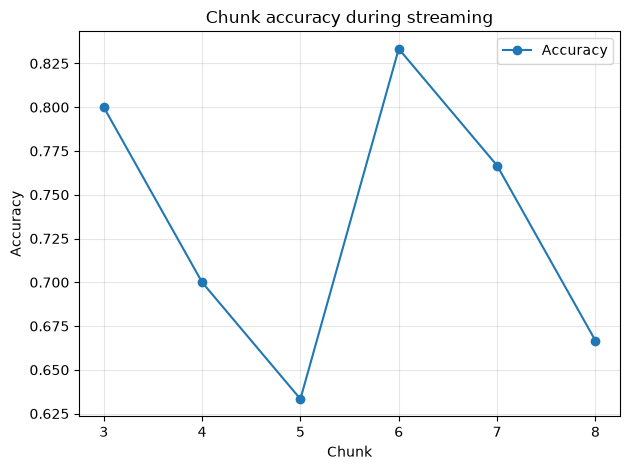

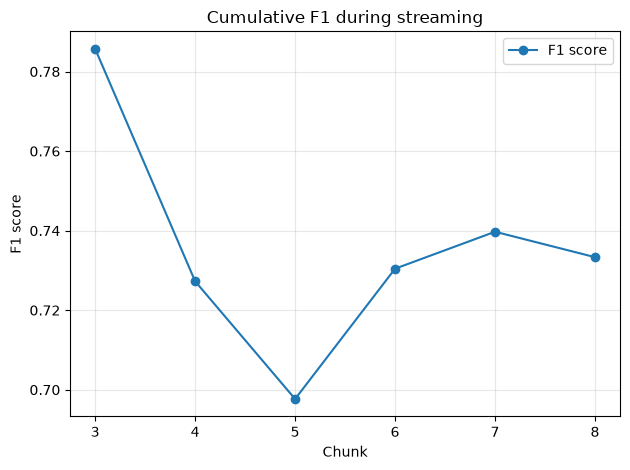

In [50]:
def save_metric_plot(history, metric, filename, title, ylabel):
    values = [record.get(metric) for record in history]
    fig = plot_metric_over_time(values, title=title, ylabel=ylabel, save_path=str(output_dir / filename), show=True)
    plt.close(fig)

save_metric_plot(trainer.history, "accuracy", "chunk_accuracy_streaming.png", "Chunk accuracy during streaming", "Accuracy")
save_metric_plot(trainer.history, "cumulative_f1", "cumulative_f1_streaming.png", "Cumulative F1 during streaming", "F1 score")


## 7. Compare predictions with actual labels

This plot compares recorded predictions with true labels for a sample of evaluated records. The initial cold-start chunk is not included because no trained model was available to make predictions at that point.


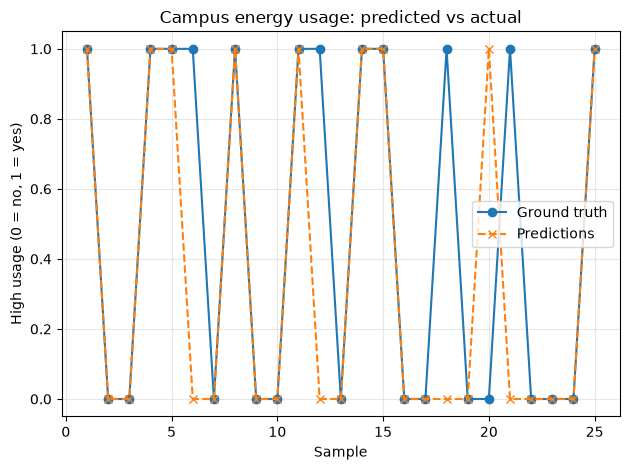

Compared total of 25 evaluated samples.


In [43]:
if len(y_true):
    n_display = min(25, len(y_true))
    fig = plot_predictions_vs_ground_truth(
        y_true[:n_display], y_pred[:n_display],
        title="Campus energy usage: predicted vs actual",
        ylabel="High usage (0 = no, 1 = yes)",
        save_path=str(output_dir / "predictions vs actual.png"),
        show=True,
    )
    plt.close(fig)
    print(f"Compared total of {n_display} evaluated samples.")
else:
    print("No predictions were recorded.")


## 8. Compare tree buffer sizes

A smaller buffer generally allows the tree to retrain more often, while a larger buffer waits for more incoming samples. This experiment compares cumulative accuracy for two buffer sizes while keeping the dataset, chunk size and other tree settings unchanged. Use the separate benchmark scripts for controlled runtime measurements.


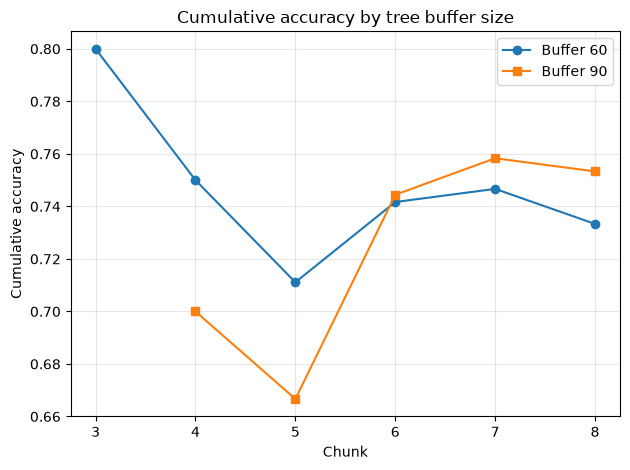

Main buffer size: 60
Comparison buffer size: 90


In [49]:
COMPARE_BUFFER_SIZE = 90
if COMPARE_BUFFER_SIZE == BUFFER_SIZE:
    raise ValueError("Choose a comparison buffer size different from BUFFER_SIZE.")

trainer_large, _, _ = run_stream(csv_path, chunk_size=CHUNK_SIZE, buffer_size=COMPARE_BUFFER_SIZE, verbose=False)
fig = compare_models(
    [r.get("cumulative_accuracy") for r in trainer.history],
    [r.get("cumulative_accuracy") for r in trainer_large.history],
    labels=(f"Buffer {BUFFER_SIZE}", f"Buffer {COMPARE_BUFFER_SIZE}"),
    title="Cumulative accuracy by tree buffer size",
    ylabel="Cumulative accuracy",
    save_path=str(output_dir / "buffer_size_comparison.png"),
    show=True,
)
plt.close(fig)
print("Main buffer size:", BUFFER_SIZE)
print("Comparison buffer size:", COMPARE_BUFFER_SIZE)


## 9. Visualise precision, recall and AUC

These additional plots show how the cumulative precision, recall and AUC change as more chunks are processed. A metric may be unavailable for a chunk, so missing values are skipped by the plotting helper.

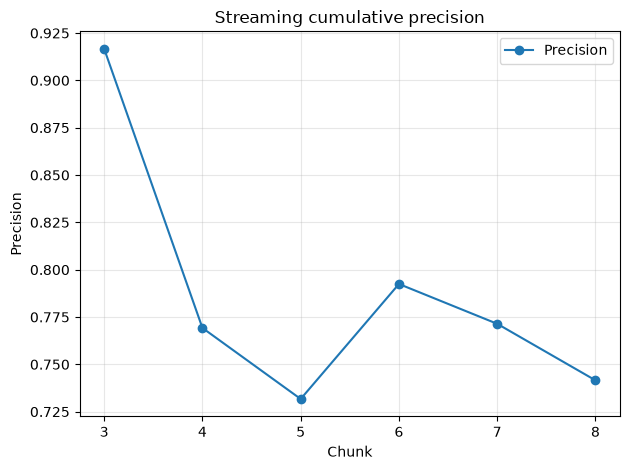

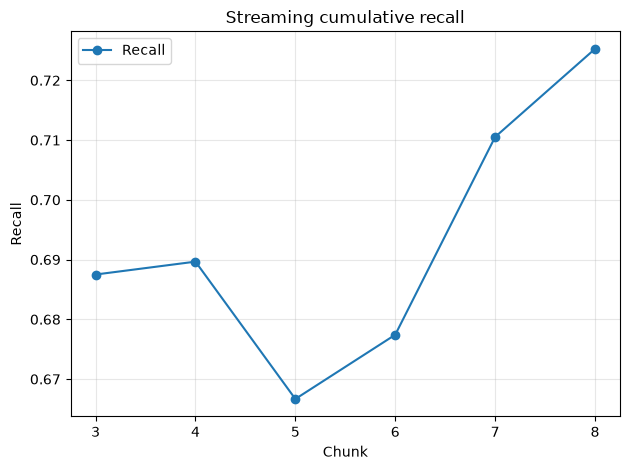

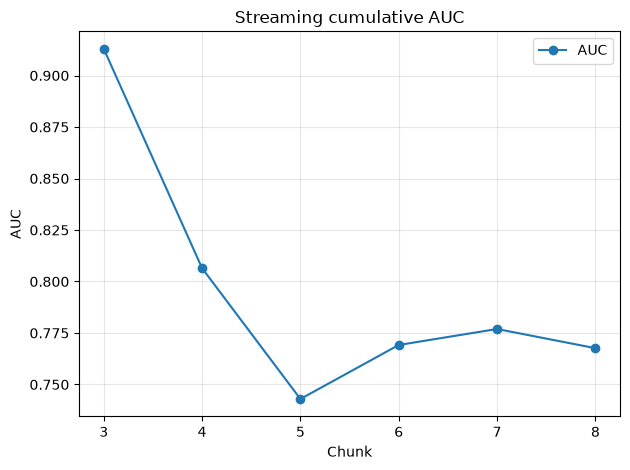

In [44]:
save_metric_plot(trainer.history, "cumulative_precision", "cumulative_precision.png", "Streaming cumulative precision", "Precision")
save_metric_plot(trainer.history, "cumulative_recall", "cumulative_recall.png", "Streaming cumulative recall", "Recall")
save_metric_plot(trainer.history, "cumulative_auc", "cumulative_auc.png", "Streaming cumulative AUC", "AUC")

## 10. View the metrics

This table makes it easier to inspect the metrics and training time recorded for each chunk. `None` means the value was not available for that chunk, usually because the model had not trained yet or a metric could not be calculated.

In [11]:
history_columns = [
    "chunk", "accuracy", "cumulative_accuracy", "cumulative_precision",
    "cumulative_recall", "cumulative_f1", "cumulative_auc", "training_time",
    "peak_memory_bytes"
]
available_columns = [
    name for name in history_columns
    if any(name in record for record in trainer.history)
]
print(" | ".join(available_columns))
for record in trainer.history:
    print(" | ".join(str(record.get(name, "N/A")) for name in available_columns))

chunk | accuracy | cumulative_accuracy | cumulative_precision | cumulative_recall | cumulative_f1 | cumulative_auc | training_time
1 | None | None | None | None | None | None | 0.0009063999750651419
2 | None | None | None | None | None | None | 0.01967589999549091
3 | 0.8 | 0.8 | 0.9166666666666666 | 0.6875 | 0.7857142857142857 | 0.9129464285714286 | 0.0006813000072725117
4 | 0.7 | 0.75 | 0.7692307692307693 | 0.6896551724137931 | 0.7272727272727274 | 0.8064516129032258 | 0.031191099958959967
5 | 0.6333333333333333 | 0.7111111111111111 | 0.7317073170731707 | 0.6666666666666666 | 0.6976744186046511 | 0.7429629629629629 | 0.00037830002838745713
6 | 0.8333333333333334 | 0.7416666666666667 | 0.7924528301886793 | 0.6774193548387096 | 0.7304347826086955 | 0.7691879866518354 | 0.030075700022280216
7 | 0.7666666666666667 | 0.7466666666666667 | 0.7714285714285715 | 0.7105263157894737 | 0.7397260273972601 | 0.7769381223328593 | 0.0007611000328324735
8 | 0.6666666666666666 | 0.7333333333333333 | 0

## 11. ROC curve

This plot uses the recorded binary predictions to show the model’s operating point against the random-classifier baseline. Since the notebook records class labels rather than prediction probabilities, this is a limited ROC view.

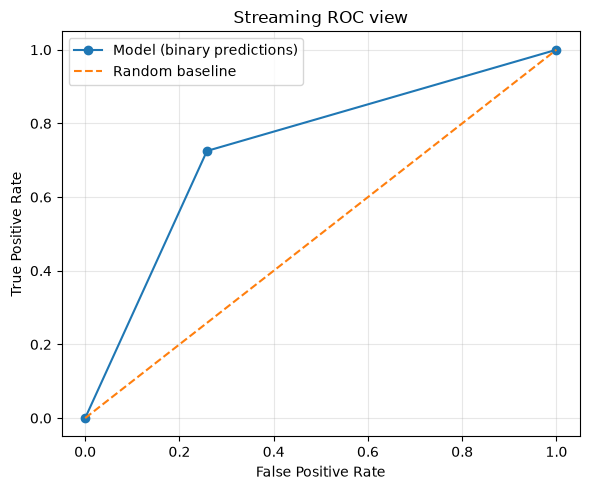

In [48]:
if len(y_true) and len(np.unique(y_true)) == 2:
    true_positive_rate = np.mean((np.asarray(y_pred) == 1) & (np.asarray(y_true) == 1)) / max(np.mean(np.asarray(y_true) == 1), 1e-12)
    false_positive_rate = np.mean((np.asarray(y_pred) == 1) & (np.asarray(y_true) == 0)) / max(np.mean(np.asarray(y_true) == 0), 1e-12)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, false_positive_rate, 1], [0, true_positive_rate, 1], marker="o", label="Model (binary predictions)")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    ax.set_title("Streaming ROC view")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "roc_curve.png", dpi=150)
    plt.show()
    plt.close(fig)


## 12. Compare several buffer sizes

The earlier comparison uses two buffer sizes. This cell extends it to three values so you can compare cumulative accuracy across different retraining intervals. These are illustrative model comparisons, not a substitute for the separate timing benchmark.

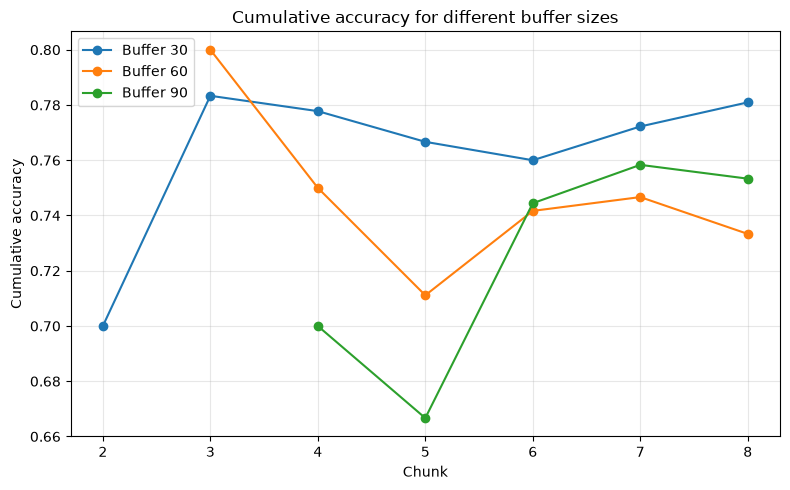

In [47]:
BUFFER_SIZES_TO_COMPARE = sorted(set([30, 60, 90]))
comparison_histories = {}
for size in BUFFER_SIZES_TO_COMPARE:
    if size == BUFFER_SIZE:
        comparison_histories[size] = trainer.history
    else:
        other_trainer, _, _ = run_stream(csv_path, chunk_size=CHUNK_SIZE, buffer_size=size, verbose=False)
        comparison_histories[size] = other_trainer.history

fig, ax = plt.subplots(figsize=(8, 5))
for size, history in comparison_histories.items():
    values = [record.get("cumulative_accuracy") for record in history]
    chunks = [i + 1 for i, value in enumerate(values) if value is not None]
    scores = [value for value in values if value is not None]
    if scores:
        ax.plot(chunks, scores, marker="o", label=f"Buffer {size}")
ax.set_title("Cumulative accuracy for different buffer sizes")
ax.set_xlabel("Chunk")
ax.set_ylabel("Cumulative accuracy")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "cumulative_accuracy_buffer_sizes_comparison.png", dpi=150)
plt.show()
plt.close(fig)

## 13. Summary

This notebook demonstrates the streaming workflow: 
1. Load CSV data in chunks through the custom I/O module
2. Standardise numeric features
3. Train a buffered decision tree incrementally
4. Evaluate each chunk before training on it
5. Inspect metric and prediction plots.
